# Módulo 2-I: Extracción de Características y Descriptores
## Trabajo Práctico: Descriptores de Forma, Contorno y Representación Geométrica

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

### Objetivos del Trabajo Práctico:
1. Comprender la diferencia entre representaciones externas (contornos) e internas (región de píxeles) de un objeto digital.
2. Implementar y analizar algoritmos clásicos de seguimiento de frontera y aproximación poligonal.
3. Estudiar la reducción de dimensionalidad (de contornos 2D a firmas 1D) y sus propiedades de invarianza.
4. Experimentar con operadores morfológicos avanzados y reducción topológica (esqueletización por afinamiento).
5. Evaluar analíticamente la robustez de los momentos de Hu ante deformaciones y transformaciones afines.

---

Nota: usa las imágenes que consideres adecuadas para los ejercicios. Explica por qué lo consideras así en cada caso.

### Celda de Configuración Inicial (Obligatoria)
Ejecutá esta celda para cargar las dependencias esenciales de procesamiento de imágenes, herramientas matemáticas e interactividad. Asegurate de subir las imágenes necesarias indicadas en el listado de assets al final del notebook antes de correr el resto de las celdas.

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox

# Función auxiliar estándar para visualización lado a lado
def mostrar_resultado(original, procesada, titulo_orig="Original", titulo_proc="Procesada", cmap_orig="gray", cmap_proc="gray"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(original, cmap=cmap_orig)
    ax[0].set_title(titulo_orig)
    ax[0].axis('off')

    ax[1].imshow(procesada, cmap=cmap_proc)
    ax[1].set_title(titulo_proc)
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

print("✅ Entorno configurado correctamente.")
print("Imágenes usadas (en la misma carpeta que el notebook): 'hueso.png' y 'jarron.png'.")

### Imágenes elegidas

- **`hueso.png`** (ejercicios 1, 2, 3 y 4): es la imagen del enunciado del ejercicio 4 (sin el marco blanco). Se eligió porque es **una sola región, sin agujeros y con frontera simple**, que es justo lo que exige el rastreo de Moore; tiene **concavidades marcadas** en las epífisis (útil para ver la insuficiencia convexa), un contorno largo y suave (ideal para ver cuánto reduce Douglas-Peucker) y una forma alargada con extremos ramificados, donde se notan bien las ramas del esqueleto.
- **`jarron.png`** (ejercicio 5): es el jarrón del enunciado del ejercicio 5 (la misma figura que usa Gonzalez & Woods para los momentos de Hu), centrado sobre **fondo negro** con margen. El fondo en 0 es importante: los momentos se calculan con la intensidad de todos los píxeles, así que un fondo gris aportaría momentos propios y las esquinas negras que aparecen al rotar romperían la invarianza.
- **Círculo y cuadrado sintéticos** (ejercicio 3): son los casos teóricos de la figura del enunciado, con firma conocida (constante y con picos en $\sqrt{2}A$), así se puede verificar que la firma está bien calculada.

---
## Ejercicio 1: Seguimiento de Frontera de Moore y Código de Cadena de Freeman

### Objetivo:
Implementar el algoritmo clásico de rastreo de frontera de Moore para obtener un contorno cerrado ordenado en sentido horario y codificarlo utilizando direcciones normalizadas de Freeman en conectividad-8.

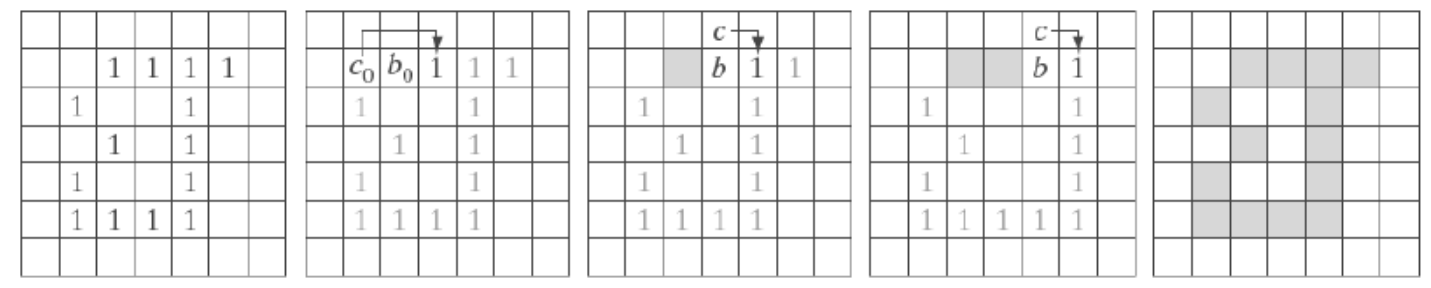

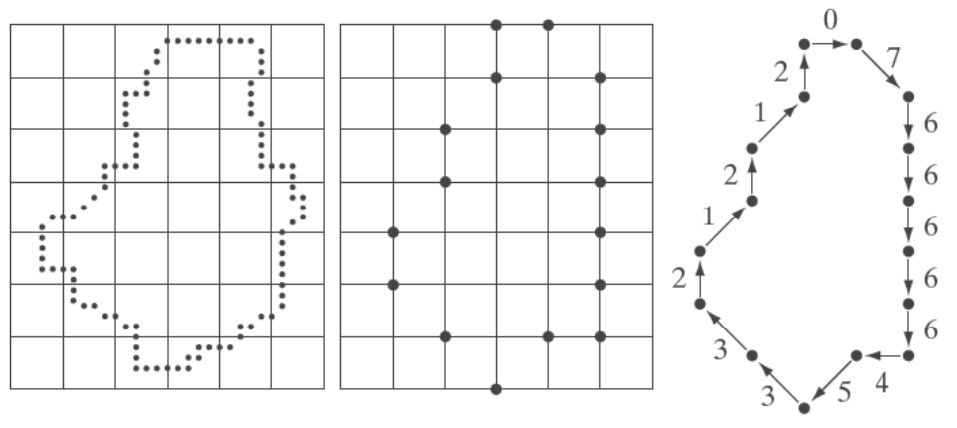

In [ ]:
def rastreo_moore(imagen_binaria):
    """
    Implementa el Algoritmo de Rastreo de Moore para obtener la frontera ordenada en sentido horario.
    Dada una región binaria (single padded region):
    """
    # Se agrega un borde de ceros: así c0 (al oeste de b0) y los vecinos de un píxel en el
    # borde de la imagen siempre existen. Al final se restan esas coordenadas extra.
    # Cualquier valor distinto de 0 cuenta como 1 (sirve para imágenes 0/1 y 0/255)
    imagen = np.pad((np.asarray(imagen_binaria) > 0).astype(np.uint8), 1)

    # Encontrar b0 (píxel de valor 1 más arriba y a la izquierda de la región)
    indices = np.argwhere(imagen == 1)
    if len(indices) == 0:
        return np.array([])
    b0 = tuple(indices[0])  # (fila, col)

    # c0 es el vecino al oeste de b0
    c0 = (b0[0], b0[1] - 1)

    # Vector de movimientos en sentido horario (vecindad-8 desde el norte)
    # n = [norte, noreste, este, sudeste, sur, sudoeste, oeste, noroeste]
    movimientos_8 = [(-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1), (-1, -1)]

    def siguiente_vecino(b, c):
        # Recorre en sentido horario los 8 vecinos de b, empezando por el que sigue a c.
        # Devuelve el primer vecino con valor 1 (n*) y el vecino examinado justo antes (el
        # nuevo c, que es fondo). Si b está aislado devuelve (None, None)
        k = movimientos_8.index((c[0] - b[0], c[1] - b[1]))
        for i in range(1, 9):
            idx = (k + i) % 8
            n = (b[0] + movimientos_8[idx][0], b[1] + movimientos_8[idx][1])
            if imagen[n] == 1:
                anterior = movimientos_8[(idx - 1) % 8]
                return n, (b[0] + anterior[0], b[1] + anterior[1])
        return None, None

    frontera = [b0]

    # FASE 1: Encontrar b1 (primer vecino con valor 1 desde c0 analizado en sentido horario)
    # 1. Identificar el índice de la dirección correspondiente a c0 respecto a b0.
    # 2. Explorar cíclicamente en sentido horario los vecinos de b0 hasta encontrar un píxel con valor 1.
    # 3. Asignar b1 y su predecesor c1.

    # --- COMPLETAR AQUÍ EL CÓDIGO PARA ENCONTRAR b1 --- #
    b1, c1 = siguiente_vecino(b0, c0)
    # -------------------------------------------------- #

    if b1 is None:
        # Región de un solo píxel: la frontera es ese píxel
        return np.array(frontera) - 1

    frontera.append(b1)
    b = b1
    c = c1

    # FASE 2: Bucle de rastreo iterativo
    max_pasos = len(imagen_binaria) * len(imagen_binaria[0])
    pasos = 0

    while pasos < max_pasos:
        # 1. Comenzar la exploración desde 'c' alrededor del píxel de frontera 'b' en sentido horario.
        # 2. Encontrar el primer vecino n* que tenga valor 1.
        # 3. Guardar n* en la lista de frontera.
        # 4. Actualizar b = n* y c = vecino inmediatamente anterior en la secuencia de búsqueda.
        # 5. Condición de parada: b == b0 y el siguiente punto a detectar sea b1.

        # --- COMPLETAR AQUÍ LA LÓGICA DE Moore --- #
        n, c_nuevo = siguiente_vecino(b, c)
        if b == b0 and n == b1:
            # Se cerró el contorno. b0 quedó repetido al final de la lista: se saca, porque
            # la frontera es cíclica (el código de Freeman agrega el paso último -> primero)
            frontera.pop()
            break
        frontera.append(n)
        b, c = n, c_nuevo
        # ---------------------------------------- #

        pasos += 1

    # Se descuenta el borde de ceros agregado al principio
    return np.array(frontera) - 1

def codigo_freeman_8(frontera):
    """
    Codifica un contorno ordenado de Moore utilizando el código de cadena de Freeman (direcciones 0-7).
    """
    if len(frontera) < 2:
        return []

    # Diccionario que mapea saltos de coordenadas (dy, dx) a direcciones de Freeman
    mapeo_direcciones = {
        (0, 1): 0, (-1, 1): 1, (-1, 0): 2, (-1, -1): 3,
        (0, -1): 4, (1, -1): 5, (1, 0): 6, (1, 1): 7
    }

    codigo = []
    # TODO: Iterar sobre la frontera y calcular la diferencia relativa para generar el código de cadena.
    # --- COMPLETAR AQUÍ EL CÓDIGO DE FREEMAN --- #
    # El contorno es cerrado: después del último punto se vuelve al primero (el % len lo hace)
    for i in range(len(frontera)):
        p, q = frontera[i], frontera[(i + 1) % len(frontera)]
        salto = (int(q[0] - p[0]), int(q[1] - p[1]))
        codigo.append(mapeo_direcciones[salto])
    # ------------------------------------------- #
    return codigo

def normalizar_punto_inicio(cadena):
    """
    Normaliza la cadena de Freeman frente a rotaciones de inicio buscando el menor número entero circular.
    """
    # TODO: Implementar el algoritmo de normalización circular de Freeman.
    # Tratando la lista como una secuencia cíclica, encontrar la permutación que represente el menor valor numérico.
    # --- COMPLETAR AQUÍ LA NORMALIZACIÓN --- #
    # Se prueban todas las rotaciones (empezar en cada posición) y se elige la menor. Todas
    # tienen la misma cantidad de dígitos, así que comparar listas elemento a elemento es lo
    # mismo que comparar los números que forman (ej. [0,7,6] < [6,0,7] porque 076 < 607)
    if len(cadena) == 0:
        return cadena
    rotaciones = [cadena[k:] + cadena[:k] for k in range(len(cadena))]
    return min(rotaciones)
    # --------------------------------------- #

In [ ]:
# Prueba del Ejercicio 1 sobre el hueso
img_hueso = cv.imread('hueso.png', cv.IMREAD_GRAYSCALE)
_, bin_hueso = cv.threshold(img_hueso, 127, 1, cv.THRESH_BINARY)

frontera_hueso = rastreo_moore(bin_hueso)
cadena = codigo_freeman_8(frontera_hueso)
cadena_norm = normalizar_punto_inicio(cadena)
print(f"Puntos de frontera: {len(frontera_hueso)}")
print("Código de Freeman (primeros 40):", cadena[:40])
print("Normalizado      (primeros 40):", cadena_norm[:40])

# Verificación 1: la frontera tiene los mismos puntos que la de OpenCV
contornos, _ = cv.findContours(bin_hueso.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
iguales = set(map(tuple, frontera_hueso.tolist())) == {(p[0][1], p[0][0]) for p in contornos[0]}
print("¿Misma frontera que cv.findContours?", iguales)

# Verificación 2: si se empieza a recorrer desde otro punto, la cadena normalizada no cambia
cadena_corrida = cadena[100:] + cadena[:100]
print("¿La normalización es invariante al punto de inicio?", normalizar_punto_inicio(cadena_corrida) == cadena_norm)

fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(bin_hueso, cmap='gray'); ax[0].set_title('Hueso binario'); ax[0].axis('off')
ax[1].imshow(bin_hueso, cmap='gray', alpha=0.25)
ax[1].plot(frontera_hueso[:, 1], frontera_hueso[:, 0], 'r-', linewidth=1)
ax[1].plot(frontera_hueso[0, 1], frontera_hueso[0, 0], 'go', markersize=8, label='b0 (inicio)')
ax[1].plot(frontera_hueso[1:20, 1], frontera_hueso[1:20, 0], 'b.', label='primeros pasos (sentido horario)')
ax[1].set_title(f'Frontera de Moore ({len(frontera_hueso)} puntos)'); ax[1].legend(loc='lower right'); ax[1].axis('off')
plt.tight_layout(); plt.show()

### 💡 Reflexión Guía - Ejercicio 1:
1. ¿Por qué el algoritmo de Moore requiere obligatoriamente que la región binaria sea de margen simple (*single padded*) y que su frontera no se auto-intersecte? Explicá qué ocurriría con los punteros lógicos de búsqueda si la región tuviera un agujero en su extremo superior izquierdo.
2. Si aplicamos una rotación geométrica de 90° a la imagen, ¿qué transformación sufre la cadena de Freeman original y cómo influye la primera diferencia de la cadena para recuperar la invarianza?

**Enlaces y Lecturas Sugeridas:**
- [Tutoriales de OpenCV - Análisis de Contornos](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html)
- [Freeman Chain Codes - Definiciones y Aplicaciones](https://en.wikipedia.org/wiki/Chain_code)

---
## Ejercicio 2: Aproximación Poligonal por División (Douglas-Peucker)

### Objetivo:
Implementar la técnica heurística de división iterativa basada en distancias perpendiculares máximas (Douglas-Peucker) para reducir el almacenamiento geométrico de un contorno.

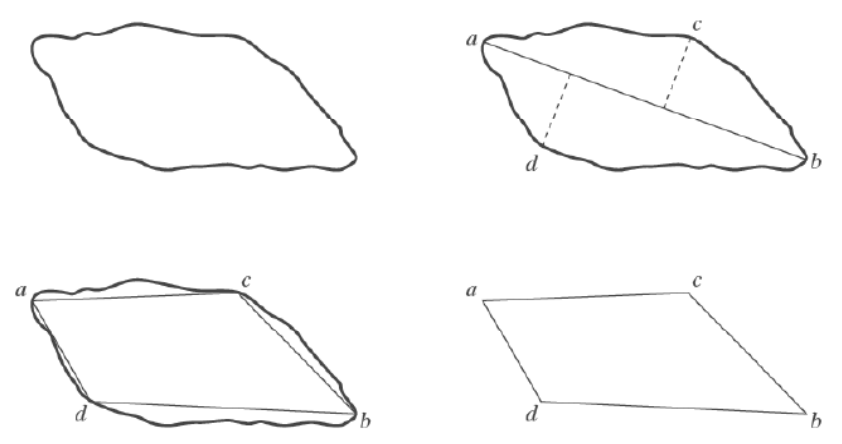

In [ ]:
def distancia_perpendicular(p, p1, p2):
    """
    Calcula la distancia perpendicular del punto p a la línea recta definida por p1 y p2.
    """
    # allclose en vez de ==: en un contorno cerrado el primer y el último punto pueden
    # diferir en ~1e-16 por redondeo, y dividir por esa norma daría distancias enormes
    if np.allclose(p1, p2):
        return np.linalg.norm(p - p1)
    # --- COMPLETAR AQUÍ LA DISTANCIA --- #
    # |(p2 - p1) x (p1 - p)| / |p2 - p1|: el producto vectorial es el área del paralelogramo
    # formado por los dos vectores; dividida por la base |p2 - p1| da la altura (la distancia)
    (x0, y0), (x1, y1), (x2, y2) = p, p1, p2
    distancia = abs((x2 - x1) * (y1 - y0) - (x1 - x0) * (y2 - y1)) / np.hypot(x2 - x1, y2 - y1)
    return distancia
    # ----------------------------------- #

def douglas_peucker(puntos, epsilon):
    """
    Algoritmo recursivo de Douglas-Peucker para aproximación poligonal.
    """
    if len(puntos) < 3:
        return puntos

    p1 = puntos[0]
    p2 = puntos[-1]

    dist_max = 0.0
    indice_max = 0

    # --- COMPLETAR AQUÍ LA BÚSQUEDA --- #
    # Sólo los puntos intermedios: los extremos están sobre la recta (distancia 0)
    for i in range(1, len(puntos) - 1):
        d = distancia_perpendicular(puntos[i], p1, p2)
        if d > dist_max:
            dist_max = d
            indice_max = i
    # ---------------------------------- #

    # Si la distancia máxima es mayor que el umbral de tolerancia epsilon, dividir de manera recursiva
    if dist_max > epsilon:
        # --- COMPLETAR RECURSIÓN --- #
        # Las dos mitades comparten el punto de división (queda como vértice)
        mitad_izq = douglas_peucker(puntos[:indice_max + 1], epsilon)
        mitad_der = douglas_peucker(puntos[indice_max:], epsilon)
        # Concatenar resultados evitando duplicar el punto intermedio
        return np.concatenate((mitad_izq[:-1], mitad_der))
        # ---------------------------- #
    else:
        return np.array([p1, p2])

# Panel Interactivo con ipywidgets para explorar el efecto de 'epsilon'
def explorar_douglas_peucker(epsilon):
    # Generar un contorno sintético con ondulaciones leves
    t = np.linspace(0, 2*np.pi, 200)
    r = 100 + 15 * np.sin(5*t)  # Trébol de 5 hojas
    x = 150 + r * np.cos(t)
    y = 150 + r * np.sin(t)
    puntos = np.column_stack((x, y))

    puntos_aprox = douglas_peucker(puntos, epsilon)

    plt.figure(figsize=(8, 8))
    plt.plot(puntos[:, 0], puntos[:, 1], 'g--', label=f"Original ({len(puntos)} puntos)")
    plt.plot(puntos_aprox[:, 0], puntos_aprox[:, 1], 'r-o', label=f"Aproximado ({len(puntos_aprox)} vértices)")
    plt.title(f"Aproximación Poligonal - Epsilon: {epsilon}")
    plt.legend()
    plt.axis('equal')
    plt.grid(True)
    plt.show()

interact(explorar_douglas_peucker, epsilon=FloatSlider(min=0.1, max=30.0, step=0.5, value=2.0))

In [ ]:
# Prueba del Ejercicio 2 sobre la frontera real del hueso (del Ejercicio 1), comparada con OpenCV
# Los puntos se pasan como (x, y) = (columna, fila). Se agrega b0 al final para cerrar el contorno
puntos_hueso = np.vstack([frontera_hueso, frontera_hueso[:1]])[:, ::-1].astype(float)

fig, ax = plt.subplots(1, 3, figsize=(15, 7))
for k, eps in enumerate([1.0, 3.0, 8.0]):
    aprox = douglas_peucker(puntos_hueso, eps)
    # approxPolyDP con closed=False recibe la misma polilínea (que ya empieza y termina en b0)
    ocv = cv.approxPolyDP(puntos_hueso.astype(np.float32).reshape(-1, 1, 2), eps, closed=False)
    ax[k].imshow(bin_hueso, cmap='gray', alpha=0.25)
    ax[k].plot(aprox[:, 0], aprox[:, 1], 'r-o', markersize=3)
    ax[k].set_title(f'epsilon = {eps}: {len(aprox)} vértices\n(cv.approxPolyDP: {len(ocv)})')
    ax[k].axis('off')
plt.suptitle(f'Douglas-Peucker sobre el hueso ({len(puntos_hueso)} puntos de frontera)')
plt.tight_layout(); plt.show()

### 💡 Reflexión Guía - Ejercicio 2:
1. En el gráfico interactivo, deslizá `epsilon` al valor máximo. ¿Cuáles son las propiedades estructurales mínimas de la forma que el algoritmo preserva incluso ante altos niveles de tolerancia epsilon?
2. Si el contorno original presenta ruido gaussiano de alta frecuencia en la frontera digital, ¿cómo afecta esto a la selección del punto de división perpendicular y cuál es la solución propuesta en la bibliografía oficial para mitigar este desvío?

**Enlaces y Lecturas Sugeridas:**
- [Ramer-Douglas-Peucker Algorithm on Wikipedia](https://en.wikipedia.org/wiki/Ramer%E2%80%93Douglas%E2%80%93Peucker_algorithm)
- [Aproximaciones Poligonales en OpenCV (`cv.approxPolyDP`)](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html)

---
## Ejercicio 3: Firmas de Contorno e Insuficiencia Convexa

### Objetivo:
Generar una representación unidimensional 1D (firma) a partir de una frontera binaria 2D utilizando la distancia al centroide en función del ángulo polar, y analizar la insuficiencia convexa como descriptor estructural.

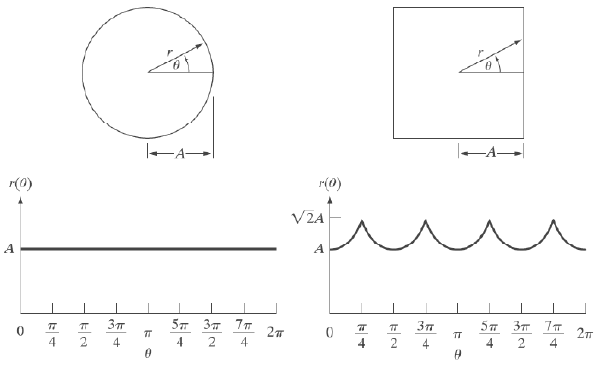

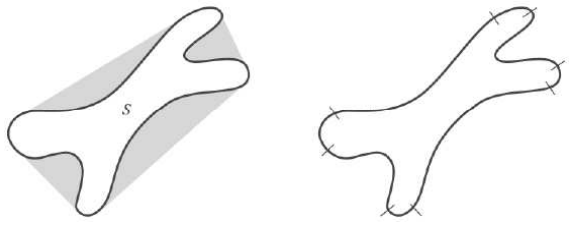

In [ ]:
def calcular_firma_polar(puntos, bins=180):
    """
    Calcula la firma de la frontera: r(theta) en función del ángulo respecto al centroide de la forma.
    """
    # Calcular el centroide geométrico de la frontera
    centroide = np.mean(puntos, axis=0)
    xc, yc = centroide[0], centroide[1]

    firma = np.zeros(bins)
    contador = np.zeros(bins)

    # --- COMPLETAR AQUÍ EL CÓDIGO DE LA FIRMA --- #
    for x, y in puntos:
        # 1. Ángulo polar respecto al centroide, en [-pi, pi]
        theta = np.arctan2(y - yc, x - xc)
        # 2. [-pi, pi] -> [0, bins). theta = pi exacto daría 'bins': se lleva al último bin
        k = min(int((theta + np.pi) / (2 * np.pi) * bins), bins - 1)
        # 3. y 4. Se acumula la distancia; al final se divide por la cantidad (promedio)
        firma[k] += np.hypot(x - xc, y - yc)
        contador[k] += 1
    # -------------------------------------------- #

    # Promedio de cada bin con puntos
    llenos = contador > 0
    firma[llenos] /= contador[llenos]
    # Reemplazar bins vacíos con el valor del bin anterior para evitar discontinuidades.
    # Es circular (el anterior al bin 0 es el último): así un bin 0 vacío no queda en 0
    inicio = np.argmax(llenos)
    for j in range(1, bins):
        i = (inicio + j) % bins
        if not llenos[i]:
            firma[i] = firma[i - 1]

    return firma

def analizar_insuficiencia_convexa(imagen_binaria):
    """
    Calcula la insuficiencia convexa D = H - S, donde H es el Convex Hull de S.
    """
    # --- COMPLETAR AQUÍ LA INSUFICIENCIA --- #
    # Manejo de tipo: cualquier valor distinto de 0 es la región (sirve con 0/1 y 0/255)
    binaria = (np.asarray(imagen_binaria) > 0).astype(np.uint8)
    # 1. Contorno externo; si hubiera varias regiones se toma la de mayor área
    contornos, _ = cv.findContours(binaria, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
    if len(contornos) == 0:
        return np.zeros_like(binaria)
    region = max(contornos, key=cv.contourArea)
    # 2. Envolvente convexa: el polígono convexo más chico que contiene a la región
    hull = cv.convexHull(region)
    # 3. Máscaras rellenas de S (la región) y de H (su envolvente)
    S = np.zeros_like(binaria)
    H = np.zeros_like(binaria)
    cv.drawContours(S, [region], -1, 1, cv.FILLED)
    cv.drawContours(H, [hull], -1, 1, cv.FILLED)
    # 4. D = H - S como operación lógica (H AND NOT S): con resta en uint8, 0 - 1 daría 255
    insuficiencia_convexa = (H.astype(bool) & ~S.astype(bool)).astype(np.uint8)
    # --------------------------------------- #
    return insuficiencia_convexa

In [ ]:
# Prueba del Ejercicio 3
# a) Firmas de un círculo y un cuadrado (los casos de la figura del enunciado)
A = 80
circulo = np.zeros((220, 220), np.uint8)
cv.circle(circulo, (110, 110), A, 1, -1)
cuadrado = np.zeros((220, 220), np.uint8)
cuadrado[110 - A:110 + A, 110 - A:110 + A] = 1

# La frontera de Moore viene como (fila, col); la firma espera (x, y) = (col, fila)
angulos = np.linspace(-180, 180, 180, endpoint=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for k, (nombre, img) in enumerate([('círculo', circulo), ('cuadrado', cuadrado)]):
    firma = calcular_firma_polar(rastreo_moore(img)[:, ::-1])
    ax[k].plot(angulos, firma)
    ax[k].axhline(A, color='gray', ls='--', label='A')
    if nombre == 'cuadrado':
        ax[k].axhline(np.sqrt(2) * A, color='r', ls='--', label='√2·A (esquinas)')
    ax[k].set_title(f'Firma del {nombre}'); ax[k].set_xlabel('θ (grados)'); ax[k].set_ylabel('r(θ)')
    ax[k].set_ylim(0, 130); ax[k].legend()

firma_hueso = calcular_firma_polar(frontera_hueso[:, ::-1])
ax[2].plot(angulos, firma_hueso)
ax[2].set_title('Firma del hueso'); ax[2].set_xlabel('θ (grados)'); ax[2].set_ylabel('r(θ)')
plt.tight_layout(); plt.show()

# b) Insuficiencia convexa del hueso, cruda y limpiada con una apertura morfológica
D = analizar_insuficiencia_convexa(bin_hueso)
D_limpia = cv.morphologyEx(D, cv.MORPH_OPEN, cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5)))
fig, ax = plt.subplots(1, 3, figsize=(12, 7))
ax[0].imshow(bin_hueso, cmap='gray'); ax[0].set_title('Región S')
ax[1].imshow(bin_hueso + 2 * D, cmap='viridis'); ax[1].set_title(f'D = H - S (cruda): {D.sum()} px')
ax[2].imshow(bin_hueso + 2 * D_limpia, cmap='viridis'); ax[2].set_title(f'D tras apertura 5x5: {D_limpia.sum()} px')
for a in ax:
    a.axis('off')
plt.tight_layout(); plt.show()

### 💡 Reflexión Guía - Ejercicio 3:
1. Si evaluamos la firma polar \(r($\theta)$\) de un círculo perfecto y la de un cuadrado perfecto, ¿qué funciones de señal 1D obtenemos en el gráfico de salida? Justificá matemáticamente las oscilaciones sinusoidales periódicas observadas en el cuadrado en base a las distancias a las esquinas.
2. La insuficiencia convexa \(D = H - S\) suele presentar pequeños parches dispersos ("ruido de borde") debido a imperfecciones en la digitalización. ¿Qué tratamiento matemático o filtro morfológico lineal/no lineal convendría aplicar para aislar únicamente las concavidades físicas reales?

**Enlaces y Lecturas Sugeridas:**
- [Convex Hull e Insuficiencia Convexa en OpenCV](https://docs.opencv.org/4.x/d7/d1d/tutorial_hull.html)
- [Signatures on Boundary Descriptors (Gonzalez & Woods)](https://www.imageprocessingplace.com/)

---
## Ejercicio 4: Esqueletización por Afinamiento Iterativo de Dos Pasos

### Objetivo:
Implementar el algoritmo matemático de afinamiento de dos pasos de regiones binarias (basado en vecindades de 8 píxeles y transiciones) para extraer el eje medio de una estructura anatómica ruidosa.

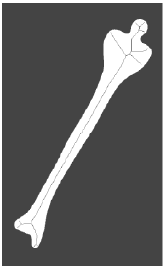

In [ ]:
def contar_transiciones_01(vecindad_8):
    """
    Calcula el número de transiciones T(p1) de 0 a 1 en sentido horario alrededor de p1.
    vecindad_8 es un vector ordenado: [p2, p3, p4, p5, p6, p7, p8, p9, p2]
    """
    # --- COMPLETAR AQUÍ EL CONTEO --- #
    # Se recorren los 8 pares consecutivos (p2,p3), (p3,p4), ..., (p9,p2): el p2 repetido al
    # final cierra el círculo
    transiciones = 0
    for i in range(len(vecindad_8) - 1):
        if vecindad_8[i] == 0 and vecindad_8[i + 1] == 1:
            transiciones += 1
    return transiciones
    # --------------------------------- #

def afinamiento_2pasos(imagen_binaria):
    """
    Aplica el algoritmo recursivo de afinamiento iterativo de dos pasos para obtener el esqueleto.
    """
    esqueleto = imagen_binaria.copy().astype(np.uint8)
    hay_cambio = True
    iteracion = 0
    max_iter = 500

    while hay_cambio and iteracion < max_iter:
        hay_cambio = False
        puntos_a_eliminar = []

        # PASO 1:
        filas, columnas = esqueleto.shape
        for r in range(1, filas - 1):
            for c in range(1, columnas - 1):
                if esqueleto[r, c] == 1:
                    # Definir vecindario horario circular
                    p2 = esqueleto[r-1, c]
                    p3 = esqueleto[r-1, c+1]
                    p4 = esqueleto[r, c+1]
                    p5 = esqueleto[r+1, c+1]
                    p6 = esqueleto[r+1, c]
                    p7 = esqueleto[r+1, c-1]
                    p8 = esqueleto[r, c-1]
                    p9 = esqueleto[r-1, c-1]

                    vecindad_suma = [p2, p3, p4, p5, p6, p7, p8, p9]
                    N_p1 = sum(vecindad_suma)
                    T_p1 = contar_transiciones_01(vecindad_suma + [p2])

                    # --- COMPLETAR AQUÍ LAS CONDICIONES 1 --- #
                    # a: no es un extremo (N=1) ni un punto interior (N=7, 8)
                    # b: sus vecinos forman un solo tramo conectado: borrarlo no parte la región
                    # c y d: está en el borde este o sur, o es una esquina noroeste
                    if (2 <= N_p1 <= 6 and T_p1 == 1
                            and p2 * p4 * p6 == 0 and p4 * p6 * p8 == 0):
                        puntos_a_eliminar.append((r, c))
                    # ---------------------------------------- #

        # Aplicar la eliminación del paso 1 de forma defensiva
        for r, c in puntos_a_eliminar:
            esqueleto[r, c] = 0
            hay_cambio = True

        puntos_a_eliminar = []
        # PASO 2:
        for r in range(1, filas - 1):
            for c in range(1, columnas - 1):
                if esqueleto[r, c] == 1:
                    p2 = esqueleto[r-1, c]
                    p3 = esqueleto[r-1, c+1]
                    p4 = esqueleto[r, c+1]
                    p5 = esqueleto[r+1, c+1]
                    p6 = esqueleto[r+1, c]
                    p7 = esqueleto[r+1, c-1]
                    p8 = esqueleto[r, c-1]
                    p9 = esqueleto[r-1, c-1]

                    vecindad_suma = [p2, p3, p4, p5, p6, p7, p8, p9]
                    N_p1 = sum(vecindad_suma)
                    T_p1 = contar_transiciones_01(vecindad_suma + [p2])

                    # --- COMPLETAR AQUÍ LAS CONDICIONES 2 --- #
                    # Iguales a las del paso 1 pero para el borde norte u oeste o la esquina
                    # sudeste: alternando los dos pasos el afinamiento avanza parejo
                    if (2 <= N_p1 <= 6 and T_p1 == 1
                            and p2 * p4 * p8 == 0 and p2 * p6 * p8 == 0):
                        puntos_a_eliminar.append((r, c))
                    # ---------------------------------------- #

        # Aplicar la eliminación del paso 2
        for r, c in puntos_a_eliminar:
            esqueleto[r, c] = 0
            hay_cambio = True

        iteracion += 1

    return esqueleto

# Ejecutar afinamiento sobre hueso ruidoso para probar el código
try:
    img_hueso = cv.imread('hueso.png', cv.IMREAD_GRAYSCALE)
    _, bin_hueso = cv.threshold(img_hueso, 127, 1, cv.THRESH_BINARY)
    esqueleto_result = afinamiento_2pasos(bin_hueso)
    mostrar_resultado(bin_hueso, esqueleto_result, "Hueso Binario", "Esqueleto Resultante")
except Exception as e:
    print("❌ Error en la ejecución: subí la imagen 'hueso.png' o verificá la implementación del TODO.")

### 💡 Reflexión Guía - Ejercicio 4:
1. En el algoritmo desarrollado, ¿cuál es el rol matemático de la condición de transición ($T(p_1) == 1$)? Justificá qué ocurriría si elimináramos esta restricción (ej. si el esqueleto se desintegraría o si se preservarían las propiedades topológicas del objeto).
2. Compará el resultado del afinamiento matemático frente a la esqueletización usando operaciones morfológicas tradicionales basadas en la resta iterativa de erosiones y aperturas (`Skeletonize`). ¿Qué diferencias observás en el ruido ("ramas espurias") en los extremos?

**Enlaces y Lecturas Sugeridas:**
- [Mathematical Morphology on Wikipedia](https://en.wikipedia.org/wiki/Mathematical_morphology)
- [SciPy Morphology API (`scipy.ndimage.binary_erosion`)](https://docs.scipy.org/doc/scipy/reference/ndimage.html)
- [Skeletonize](https://scikit-image.org/docs/stable/auto_examples/edges/plot_skeleton.html)

### Extra: Usar el algoritmo de Zhang-Suen optimizado en OpenCV:

* [Hilo de StackOverflow sobre Esqueletización en OpenCV](https://stackoverflow.com/questions/33095476/is-there-a-build-in-function-to-do-skeletonization)

> En esta discusión se explica paso a paso cómo la comunidad integró este algoritmo en el módulo extendido de OpenCV (`opencv-contrib-python`).

Cómo se usa en código (el módulo `ximgproc`):

> import cv2
>
> imagen = cv2.imread('anatomia.png', cv2.IMREAD_GRAYSCALE)
>
> \# Binarizas la imagen (fondo negro, objeto blanco)
>
> _, binaria = cv2.threshold(imagen, 127, 255, cv2.THRESH_BINARY)
>
> \# Aplicas Zhang-Suen directamente
>
> esqueleto = cv2.ximgproc.thinning(binaria, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)



In [ ]:
# Comparación (Reflexión 2 y Extra): nuestro afinamiento vs Zhang-Suen de OpenCV vs el
# esqueleto morfológico clásico (unión de erosiones menos sus aperturas)
def esqueleto_morfologico(binaria):
    # S(A) = U_k [ (A erosionada k veces) - apertura(A erosionada k veces) ]
    kernel = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
    erosionada = binaria.astype(np.uint8).copy()
    esqueleto = np.zeros_like(erosionada)
    while erosionada.any():
        apertura = cv.morphologyEx(erosionada, cv.MORPH_OPEN, kernel)
        esqueleto |= erosionada & (1 - apertura)
        erosionada = cv.erode(erosionada, kernel)
    return esqueleto

paneles = [(esqueleto_result, 'Nuestro afinamiento (2 pasos)')]
if hasattr(cv, 'ximgproc'):
    zs = cv.ximgproc.thinning(bin_hueso * 255, thinningType=cv.ximgproc.THINNING_ZHANGSUEN)
    paneles.append((zs // 255, 'cv.ximgproc Zhang-Suen'))
    print("¿Idéntico a Zhang-Suen de OpenCV?", np.array_equal(esqueleto_result, zs // 255))
paneles.append((esqueleto_morfologico(bin_hueso), 'Esqueleto morfológico'))

fig, ax = plt.subplots(1, len(paneles), figsize=(4 * len(paneles), 7))
for a, (img, titulo) in zip(ax, paneles):
    a.imshow(bin_hueso, cmap='gray', alpha=0.3)
    a.imshow(np.ma.masked_equal(img, 0), cmap='autumn')
    a.set_title(f'{titulo}\n{int(img.sum())} px'); a.axis('off')
plt.tight_layout(); plt.show()

---
## Ejercicio 5: Momentos de Intensidad 2D y Momentos Invariantes de Hu

### Objetivo:
Calcular los momentos centrales normalizados de una imagen bidimensional y evaluar la invarianza matemática absoluta de los momentos de Hu mediante rotación, traslación y cambio de escala interactivo.

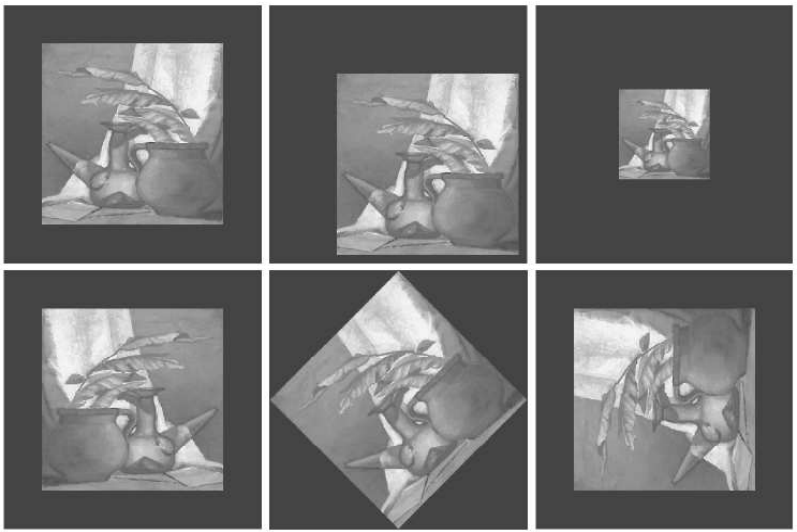

In [ ]:
def calcular_momentos_centrales(imagen):
    """
    Calcula los momentos centralizados normalizados (eta_pq) hasta tercer orden para una imagen dada.
    """
    filas, columnas = imagen.shape
    y, x = np.mgrid[:filas, :columnas]

    # Momentos estándar m_pq
    m00 = np.sum(imagen)
    if m00 == 0:
        return {}

    m10 = np.sum(x * imagen)
    m01 = np.sum(y * imagen)

    # Calcular las coordenadas del centroide geométrico (x_bar, y_bar)
    x_bar = m10 / m00
    y_bar = m01 / m00

    # Centralizar coordenadas
    x_c = x - x_bar
    y_c = y - y_bar

    momentos_centrales = {}

    # --- COMPLETAR AQUÍ LA CENTRALIZACIÓN Y NORMALIZACIÓN --- #
    # mu_pq: como m_pq pero respecto del centroide -> no cambia al trasladar la imagen
    # eta_pq: mu_pq dividido por m00^gamma -> no cambia al escalarla
    for p, q in [(2, 0), (0, 2), (1, 1), (3, 0), (0, 3), (1, 2), (2, 1)]:
        mu = np.sum((x_c ** p) * (y_c ** q) * imagen)
        gamma = (p + q) / 2 + 1
        momentos_centrales[f'mu{p}{q}'] = mu
        momentos_centrales[f'eta{p}{q}'] = mu / (float(m00) ** gamma)
    # --------------------------------------------------------- #

    return momentos_centrales

def calcular_hu_invariantes(momentos_normalizados):
    """
    Deriva los primeros 4 momentos de Hu en base a los momentos centrales normalizados (eta).
    """
    # Obtener valores de la estructura
    eta20 = momentos_normalizados.get('eta20', 0)
    eta02 = momentos_normalizados.get('eta02', 0)
    eta11 = momentos_normalizados.get('eta11', 0)
    eta30 = momentos_normalizados.get('eta30', 0)
    eta03 = momentos_normalizados.get('eta03', 0)
    eta12 = momentos_normalizados.get('eta12', 0)
    eta21 = momentos_normalizados.get('eta21', 0)

    # --- COMPLETAR EQUIVALENTES DE HU --- #
    # Combinaciones de los eta que además no cambian al rotar
    phi1 = eta20 + eta02
    phi2 = (eta20 - eta02) ** 2 + 4 * eta11 ** 2
    phi3 = (eta30 - 3 * eta12) ** 2 + (3 * eta21 - eta03) ** 2
    phi4 = (eta30 + eta12) ** 2 + (eta21 + eta03) ** 2
    # ------------------------------------ #

    # Aplicación del escalado logarítmico para visualización amigable de magnitud
    # hu_log = -sign(phi) * log10(|phi|)
    hu_logs = []
    for phi in [phi1, phi2, phi3, phi4]:
        if phi != 0:
            hu_logs.append(-np.sign(phi) * np.log10(np.abs(phi)))
        else:
            hu_logs.append(0.0)

    return hu_logs

# Panel Interactivo: aplicar transformaciones y verificar la invarianza de los momentos de Hu
def explorar_invarianza_hu(angulo, escala, tx, ty):
    try:
        img = cv.imread('jarron.png', cv.IMREAD_GRAYSCALE)
        if img is None:
            # Generar imagen sintética si no se encuentra el archivo
            img = np.zeros((200, 200), dtype=np.uint8)
            cv.rectangle(img, (60, 60), (140, 140), 255, -1)
            cv.circle(img, (100, 100), 50, 0, -1)

        filas, columnas = img.shape

        # 1. Aplicar Rotación y Escala usando la matriz de transformación afín de OpenCV
        M = cv.getRotationMatrix2D((columnas/2, filas/2), angulo, escala)
        # 2. Agregar componentes de Traslación tx y ty a la matriz afín
        M[0, 2] += tx
        M[1, 2] += ty

        img_transformada = cv.warpAffine(img, M, (columnas, filas))

        # Calcular momentos
        momentos_norm_orig = calcular_momentos_centrales(img)
        momentos_norm_trans = calcular_momentos_centrales(img_transformada)

        hu_orig = calcular_hu_invariantes(momentos_norm_orig)
        hu_trans = calcular_hu_invariantes(momentos_norm_trans)

        # Renderizado
        fig, ax = plt.subplots(1, 2, figsize=(12, 6))
        ax[0].imshow(img, cmap='gray')
        ax[0].set_title("Jarrón Original")
        ax[0].axis('off')

        ax[1].imshow(img_transformada, cmap='gray')
        ax[1].set_title("Jarrón Transformado")
        ax[1].axis('off')
        plt.tight_layout()
        plt.show()

        print(f"====== COMPARACIÓN DE MOMENTOS DE HU (LOG SCALE) ======")
        print(f"Momentos Originales:     phi1={hu_orig[0]:.4f}, phi2={hu_orig[1]:.4f}, phi3={hu_orig[2]:.4f}, phi4={hu_orig[3]:.4f}")
        print(f"Momentos Transformados:  phi1={hu_trans[0]:.4f}, phi2={hu_trans[1]:.4f}, phi3={hu_trans[2]:.4f}, phi4={hu_trans[3]:.4f}")

        # Verificación contra OpenCV (mismas fórmulas, misma escala logarítmica)
        hu_cv = cv.HuMoments(cv.moments(img_transformada)).ravel()[:4]
        hu_cv_log = [-np.sign(h) * np.log10(np.abs(h)) if h != 0 else 0.0 for h in hu_cv]
        print(f"cv.HuMoments (transf.):  phi1={hu_cv_log[0]:.4f}, phi2={hu_cv_log[1]:.4f}, phi3={hu_cv_log[2]:.4f}, phi4={hu_cv_log[3]:.4f}")

    except Exception as e:
        print("❌ Error en la ejecución: subí la imagen 'jarron.png' o verificá la implementación del TODO.")
        print("Mensaje de error:", e)

interact(explorar_invarianza_hu,
         angulo=IntSlider(min=-180, max=180, step=5, value=0),
         escala=FloatSlider(min=0.4, max=1.8, step=0.1, value=1.0),
         tx=IntSlider(min=-50, max=50, step=5, value=0),
         ty=IntSlider(min=-50, max=50, step=5, value=0))

### 💡 Reflexión Guía - Ejercicio 5:
1. Observá la tabla de resultados numéricos impresos al desplazar el control de `escala`. ¿Por qué se introduce un factor de corrección exponencial ($\gamma$) en el denominador del cálculo del momento central normalizado ($\eta_{pq}$)? Demostrá analíticamente cómo cancela este factor los cambios de escala proporcionales sobre el área ($m_{00}$).
2. Desplazá el control de traslación horizontal `tx` e Y `ty` hacia los límites máximos permitidos en el slider. Si el jarrón se traslada tanto que una fracción de la forma se desplaza "fuera del margen" de la grilla de la imagen, ¿qué ocurre con el valor calculado de ($\phi_1$) y por qué se rompe la invarianza matemática?

**Enlaces y Lecturas Sugeridas:**
- [Hu Moments on Wikipedia](https://en.wikipedia.org/wiki/Image_moment)
- [Momentos de Hu en OpenCV (`cv.HuMoments`)](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gab27bfa406c7df7d4e56c598aa3ca3148)